# PyPSA network maps

The study region and the solved networks on a map, for the supplementary
information: at each cluster a pie of the generation technologies' capacity,
over the AC lines and DC links. Each line is drawn pale at its final rating with
its existing rating solid on top, so the pale margin is the reinforcement. Pie
area and line width are linear in GW, on one scale across every map.

Capacities are read at the electricity port, as `build_network_summary` reads
them, so a gas plant counts its electrical rating; the per-technology totals are
those of `pypsa_summary.ipynb`. Which technologies are drawn and how is
`plotting.network_map` in `config/default.yaml`.

1. **Study region** — the modelled countries.
2. **Reference network** — the reference system scenario alone.
3. **System scenarios** — every solved network, one panel each, titled by the
   scenario standing for it.

Which networks, their titles and which is the reference come from
`build/pypsa/system_networks.csv` (rule `list_system_networks`). Run by the
`visualise_pypsa_maps` rule, or interactively (paths resolve to the repo root)
once that table exists.

In [ ]:
import sys
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.lines as mlines
import pandas as pd
import pypsa
import yaml
from pypsa.plot import add_legend_circles

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402 — needs the path above
from info_schemas import GridCarrier, SystemNetwork  # noqa: E402
from pypsa_helpers import forward_dc_links  # noqa: E402

try:
    paths = dict(
        system_networks=snakemake.input.system_networks,  # noqa: F821 — injected by the snakemake notebook rule
        country_shapes=snakemake.input.country_shapes,  # noqa: F821
        figures=snakemake.output.figures,  # noqa: F821
    )
    technology_info = dict(snakemake.params.technology_info)  # noqa: F821
    electricity_bus_carriers = list(snakemake.params.electricity_bus_carriers)  # noqa: F821
    style = dict(snakemake.params.plotting)  # noqa: F821
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    technology_info = config["technology_info"]
    electricity_bus_carriers = config["pypsa"]["electricity_bus_carriers"]
    style = config["plotting"]
    paths = dict(
        system_networks=repo / "build/pypsa/system_networks.csv",
        country_shapes=repo / "pypsa-eur/resources/country_shapes.geojson",
        figures=repo / "build/pypsa/maps",
    )

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)
ink = style["ink"]
geometry = style["network_map"]

# Network paths are relative to the repo root.
system_networks = pd.read_csv(paths["system_networks"], index_col=SystemNetwork.scenario)
reference = system_networks.index[system_networks[SystemNetwork.reference]].item()

MW_PER_GW = 1e3

generation = geometry["generation"]
generation_owner = {
    carrier: technology
    for technology in generation
    for carrier in technology_info[technology]["pypsa_carriers"]
}
grid_owner = {
    carrier: technology
    for technology, info in technology_info.items()
    for carrier in info["pypsa_carriers"]
    if carrier in (GridCarrier.ac, GridCarrier.dc)
}
colors = {technology: info["color"] for technology, info in technology_info.items()}
nice_names = {technology: info["nice_name"] for technology, info in technology_info.items()}
line_color = colors[grid_owner[GridCarrier.ac]]
link_color = colors[grid_owner[GridCarrier.dc]]
projection = getattr(ccrs, geometry["projection"])()

In [2]:
def generation_capacity(n):
    """GW per (cluster, technology), read at the electricity port as the summary
    reads it, so a gas plant counts its electrical rating rather than its fuel."""
    capacity = n.statistics.optimal_capacity(
        bus_carrier=electricity_bus_carriers,
        groupby=["location", "carrier"],
        nice_names=False,
    ).droplevel("component")
    capacity = capacity[capacity.index.get_level_values("carrier").isin(generation_owner)]
    return (
        capacity.rename(generation_owner, level="carrier").groupby(level=[0, 1]).sum()
        / MW_PER_GW
    )


def draw_network(ax, n, title):
    """Generation pies over the AC lines and forward DC links, each branch drawn
    pale at its final rating and solid at its existing one."""
    lines = n.lines[n.lines.carrier == GridCarrier.ac]
    links = forward_dc_links(n)
    mw_per_point = geometry["gw_per_point"] * MW_PER_GW
    common = dict(
        ax=ax,
        boundaries=geometry["boundaries"],
        branch_components=["Line", "Link"],
        line_color=line_color,
        link_color=link_color,
    )
    n.plot.map(
        bus_size=generation_capacity(n) / geometry["gw_per_square_degree"],
        bus_color=colors,
        line_width=lines.s_nom_opt / mw_per_point,
        link_width=links.p_nom_opt / mw_per_point,
        line_alpha=geometry["reinforcement_alpha"],
        link_alpha=geometry["reinforcement_alpha"],
        geomap_color={"land": ink["grid"], "border": ink["surface"], "coastline": "none"},
        **common,
    )
    # No land here, or it would be painted over the pale layer.
    n.plot.map(
        bus_size=0,
        line_width=lines.s_nom / mw_per_point,
        link_width=links.p_nom / mw_per_point,
        geomap_color={"border": ink["surface"], "coastline": "none"},
        **common,
    )
    plotting.panel_title(ax, style, title, None)


def map_keys(fig, ax, anchor):
    """The pie sizes hung off `ax`, since they only read against a map's scale,
    at `anchor` in its axes fraction; the colours and line widths under the figure.
    """
    sizes = geometry["capacity_key_gw"]
    capacity = add_legend_circles(
        ax,
        [gw / geometry["gw_per_square_degree"] for gw in sizes],
        [f"{gw} GW" for gw in sizes],
        patch_kw={"facecolor": ink["muted"], "linewidth": 0},
        legend_kw={
            "loc": "upper left",
            "bbox_to_anchor": anchor,
            "frameon": False,
            "title": "Generation capacity",
            "labelspacing": geometry["capacity_key_spacing"],
            "handletextpad": 1.2,
        },
    )
    # Out of the layout, so that hanging it beside a panel does not shrink the grid.
    capacity.set_in_layout(False)

    technologies = fig.legend(
        handles=plotting.patch_handles(generation, colors, nice_names),
        title="Generation", frameon=False, ncol=2, loc="outside lower left",
    )
    line = dict(color=ink["secondary"], linewidth=2.0)
    transmission = fig.legend(
        handles=[
            mlines.Line2D([], [], **line | {"color": line_color},
                          label=nice_names[grid_owner[GridCarrier.ac]]),
            mlines.Line2D([], [], **line | {"color": link_color},
                          label=nice_names[grid_owner[GridCarrier.dc]]),
            mlines.Line2D([], [], **line, label="Existing"),
            mlines.Line2D([], [], **line, alpha=geometry["reinforcement_alpha"],
                          label="Reinforcement"),
            *[
                mlines.Line2D([], [], **line | {"linewidth": gw / geometry["gw_per_point"]},
                              label=f"{gw} GW")
                for gw in geometry["width_key_gw"]
            ],
        ],
        title="Transmission", frameon=False, ncol=1, loc="outside lower right",
    )
    return capacity, technologies, transmission

## Study region

The countries of the PyPSA-Eur `countries` list, as PyPSA-Eur draws them, over
the rest of the map's land.

In [ ]:
countries = gpd.read_file(paths["country_shapes"])
fig, (ax,) = plotting.page_grid(
    1, style, max_columns=1, panel_aspect=geometry["panel_aspect"],
    subplot_kw={"projection": projection},
)
ax.set_extent(geometry["boundaries"], crs=ccrs.PlateCarree())
resolution = geometry["geomap_resolution"]
ax.add_feature(cfeature.LAND.with_scale(resolution), facecolor=ink["grid"])
ax.add_feature(
    cfeature.BORDERS.with_scale(resolution),
    edgecolor=ink["surface"], linewidth=geometry["border_width"],
)
ax.add_geometries(
    countries.geometry, crs=ccrs.PlateCarree(),
    facecolor=ink["muted"], edgecolor=ink["surface"], linewidth=geometry["border_width"],
)
plotting.save_figure(fig, figures_dir, "study_region", style)

## Reference network

The pie key sits over the Atlantic, the one part of the map the network leaves
empty.

INFO:pypsa.network.io:New version 1.3.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks
/var/folders/cd/3symzw7d0833vd8qj4shbrl80000gp/T/ipykernel_52843/3700857948.py:55: UserWarning: When combining n.plot() with other plots on a geographical axis, ensure n.plot() is called first or the final axis extent is set initially (ax.set_extent(boundaries, crs=crs)) for consistent legend circle sizes.
  capacity = add_legend_circles(
INFO:fontTools.subset:maxp pruned
INFO:fontTools.subset:cmap pruned
INFO:fontTools.subset:kern pruned
INFO:fontTools.subset:post pruned
INFO:fontTools.subset:feat dropped
INFO:fontTools.subset:fond dropped
INFO:fontTools.subset:meta dropped
INFO:fontTools.subset:morx dropped
INFO:fontTools.subset:glyf pruned
INFO:fontTools.subset:Added gid0 to subset
INFO:fontTools.subset:Added first four glyphs to subset
INFO:fontTools.

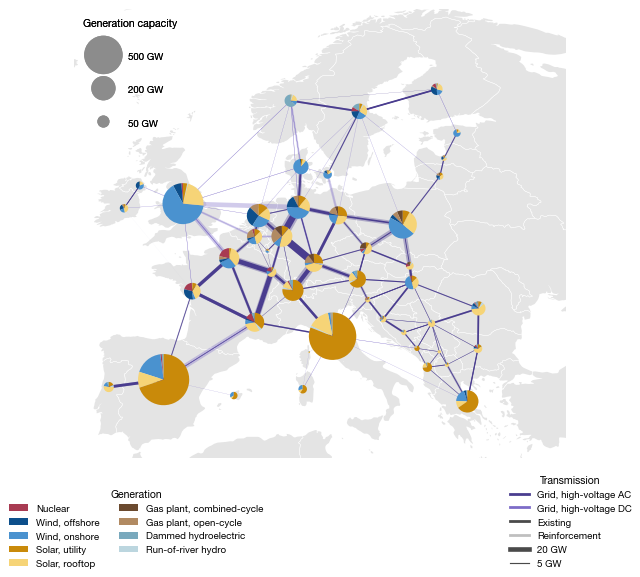

In [3]:
fig, (ax,) = plotting.page_grid(
    1, style, max_columns=1, panel_aspect=geometry["panel_aspect"],
    subplot_kw={"projection": projection},
)
network = pypsa.Network(repo / system_networks.loc[reference, SystemNetwork.network])
draw_network(ax, network, None)
plotting.save_figure(fig, figures_dir, "network_map_reference", style, map_keys(fig, ax, (0, 1)))

## System scenarios

One panel per solved network, in config order, on the reference map's scale.
The substitution scenarios share the reference network and so have no map of their
own. Networks are opened one at a time, as each is large in memory.

INFO:pypsa.network.io:New version 1.3.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.3.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.3.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.3.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.3.0 available! (Current:

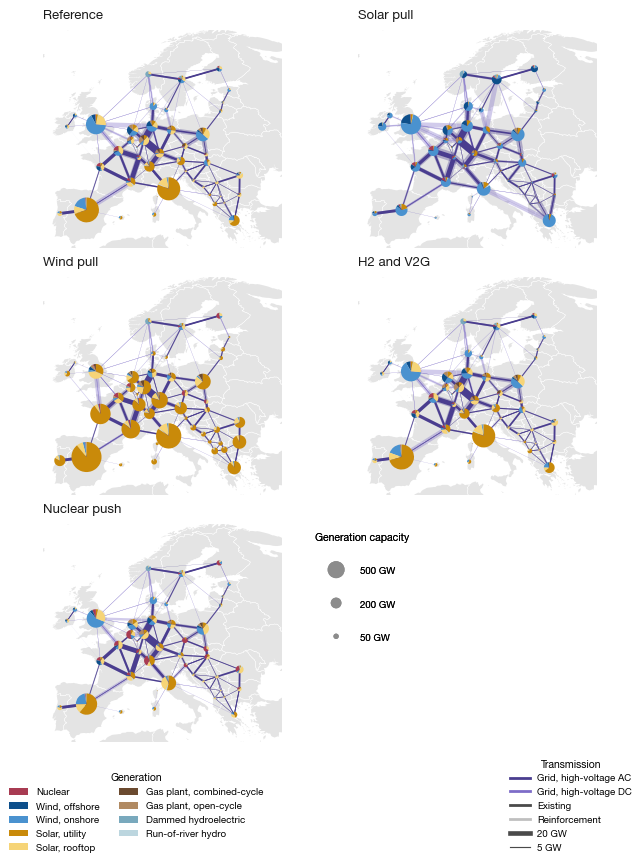

In [4]:
fig, axes = plotting.page_grid(
    len(system_networks), style, max_columns=geometry["max_columns"],
    panel_aspect=geometry["panel_aspect"], subplot_kw={"projection": projection},
)
for ax, (_, row) in zip(axes, system_networks.iterrows()):
    network = pypsa.Network(repo / row[SystemNetwork.network])
    draw_network(ax, network, row[SystemNetwork.nice_name])
# The pie key goes in the cell the last row leaves empty.
plotting.save_figure(
    fig, figures_dir, "network_map_scenarios", style, map_keys(fig, axes[-1], (1.1, 1))
)